# Task 1 — Model round 5: error-context candidates

Read `eda_error_context_v2` by its JSON card and compare three prespecified feature groups against the saved 38-feature LightGBM procedure. The six outer splits match Round 3/4 exactly (3 folds × 2 repeats). Each candidate uses the same LightGBM settings and a **fixed 0.400 decision threshold** to isolate the feature-set effect. The baseline's saved OOF probabilities are also rescored at 0.400. This comparison is exploratory because its hypotheses came from earlier OOF errors; the two repeats reuse the same accounts. Test is never used for fitting or evaluation.

Each candidate has its own cell that performs CV, fits the full-data model, saves it, and records a distinct `macro_F2_outer_cv6_fixed040` evaluation. Existing artifacts are loaded instead of retrained.

In [1]:
from pathlib import Path
import json
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "pipeline" / "save_model.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.pipeline.random_seed import set_seed
from src.pipeline.save_model import save_model
from src.pipeline.evaluate_model import evaluate_model
from src.pipeline.read_evalutate_summarize import read_evaluation_index
SEED = set_seed()

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import fbeta_score
from sklearn.model_selection import RepeatedStratifiedKFold, FixedThresholdClassifier
sns.set_theme(style="whitegrid")

SRC = ROOT/"src"
TASK = SRC/"task1"
DATA_NAME = "eda_error_context_v2"
ID,TARGET = "player_id","is_cheater"
FIXED_THRESHOLD = 0.4
data_card = json.loads((TASK/"data"/"eda"/f"{DATA_NAME}.json").read_text(encoding="utf-8"))
def read_split(split):
    return pd.read_parquet(SRC/data_card["splits"][split]["path"])
train, test = read_split("train"), read_split("test")
assert train.drop(columns=TARGET).columns.tolist()==test.columns.tolist()
assert train[TARGET].notna().all() and train[ID].is_unique
y=train[TARGET].astype(int).reset_index(drop=True)
source_name="t1_lgbm_original_tuned_v1"
source_card=json.loads((TASK/"save"/f"{source_name}.json").read_text(encoding="utf-8"))
source_model=joblib.load(SRC/source_card["model_path"])
selected_card=json.loads((TASK/"save"/"t1_lgbm_combined_pruned_cv6_full_v1.json").read_text(encoding="utf-8"))
BASE=list(selected_card["card"]["selected_features"])
CONTEXT=list(data_card["card"]["candidate_groups"]["context"])
BEHAVIOR=list(data_card["card"]["candidate_groups"]["behavior"])
assert len(BASE)==38 and len(CONTEXT)==len(BEHAVIOR)==4
assert set(BASE+CONTEXT+BEHAVIOR)<=set(test.columns)
VARIANTS={"context":BASE+CONTEXT,"behavior":BASE+BEHAVIOR,
          "all":BASE+CONTEXT+BEHAVIOR}
outer_cv=RepeatedStratifiedKFold(n_splits=3,n_repeats=2,random_state=SEED)
splits=list(outer_cv.split(train[BASE],y))
assert len(splits)==6
print("Data:",DATA_NAME,len(train),"labeled rows; source model:",source_name)
print("Candidate feature counts:",{k:len(v) for k,v in VARIANTS.items()})

Data: eda_error_context_v2 90816 labeled rows; source model: t1_lgbm_original_tuned_v1
Candidate feature counts: {'context': 42, 'behavior': 42, 'all': 46}


## 1. Reconstruct the fixed-threshold baseline on exactly these folds

The existing OOF files store probabilities from the 38-feature model. Their folds are checked against the current split generator, then all predictions are made with threshold 0.400. No baseline fit is repeated.

In [2]:
result_dir=TASK/"models"/"results"
baseline_parts=[]
for repeat,suffix in [(1,""),(2,"_repeat2")]:
    frame=pd.read_parquet(result_dir/f"round4_lgbm_combined_pruned{suffix}_oof_v1.parquet")
    baseline_parts.append(frame)
baseline=pd.concat(baseline_parts,ignore_index=True)
assert len(baseline)==2*len(train)
for fold,(_,valid_idx) in enumerate(splits,1):
    part=baseline[baseline.fold==fold].sort_values("row_index")
    assert np.array_equal(part.row_index.to_numpy(),np.sort(valid_idx))
    assert np.array_equal(part[ID].to_numpy(),train.iloc[part.row_index][ID].to_numpy())
    assert np.array_equal(part.true.to_numpy(),y.iloc[part.row_index].to_numpy())
baseline["pred_fixed"]=(baseline.prob>=FIXED_THRESHOLD).astype(int)
def fold_scores(frame,pred_col):
    rows=[]
    for fold,group in frame.groupby("fold",sort=True):
        rows.append({"fold":int(fold),"macro_F2":fbeta_score(group.true,group[pred_col],beta=2,average="macro",zero_division=0),
                     "F2_legitimate":fbeta_score(group.true,group[pred_col],beta=2,pos_label=0,zero_division=0),
                     "F2_cheater":fbeta_score(group.true,group[pred_col],beta=2,pos_label=1,zero_division=0)})
    return pd.DataFrame(rows)
baseline_scores=fold_scores(baseline,"pred_fixed")
display(baseline_scores.round(5))
print("Baseline mean macro F2 at fixed 0.400:",round(baseline_scores.macro_F2.mean(),5))
print("Prior inner-CV-tuned mean macro F2:",round(selected_card["card"]["outer_cv_mean_macro_F2"],5))

,fold,macro_F2,F2_legitimate,F2_cheater
0,1,0.77831,0.81713,0.73949
1,2,0.77765,0.81914,0.73617
2,3,0.77759,0.81950,0.73567
3,4,0.77484,0.81406,0.73562
4,5,0.77636,0.82054,0.73218
5,6,0.77755,0.81905,0.73606


Baseline mean macro F2 at fixed 0.400: 0.77705
Prior inner-CV-tuned mean macro F2: 0.77733


## 2. Shared experiment helper

`run_variant` verifies the saved dataset and names before fitting. It records OOF predictions and fold scores, then saves a model refit on every labeled row with the same feature selector and fixed threshold. The CV estimate is recorded under its own metric name and is not represented as a new holdout score for the full fit.

In [3]:
def run_variant(label,features):
    name=f"t1_lgbm_{label}_fixed040_cv6_v3"
    model_path=TASK/"save"/f"{name}.joblib"
    card_path=TASK/"save"/f"{name}.json"
    eval_path=TASK/"save"/f"{name}-evaluation.json"
    oof_path=result_dir/f"{name}-oof.parquet"
    oof_card_path=result_dir/f"{name}-oof.json"
    key={"data_name":DATA_NAME,"data_created_at":data_card["created_at"],
         "source_name":source_name,"source_created_at":source_card["created_at"],
         "seed":SEED,"outer":"3-fold x 2 repeats","threshold":FIXED_THRESHOLD,
         "features":features}
    if oof_path.exists()!=oof_card_path.exists():
        raise RuntimeError(f"Incomplete OOF artifact: {name}")
    if oof_path.exists():
        saved=json.loads(oof_card_path.read_text(encoding="utf-8"))
        if saved["key"]!=key: raise ValueError(f"Different OOF lineage: {name}")
        oof=pd.read_parquet(oof_path)
        print("Loaded OOF:",name)
    else:
        if model_path.exists() or card_path.exists() or eval_path.exists():
            raise RuntimeError(f"Saved model without OOF: inspect {name}")
        rows=[]
        X=train[features]
        for fold,(train_idx,valid_idx) in enumerate(splits,1):
            model=clone(source_model)
            model.fit(X.iloc[train_idx],y.iloc[train_idx])
            probability=model.predict_proba(X.iloc[valid_idx])[:,1]
            rows.append(pd.DataFrame({"row_index":valid_idx,"fold":fold,
                "true":y.iloc[valid_idx].to_numpy(),"prob":probability,
                "pred_fixed":(probability>=FIXED_THRESHOLD).astype("int8")}))
            print(name,"fold",fold,"done")
        oof=pd.concat(rows,ignore_index=True)
        result_dir.mkdir(parents=True,exist_ok=True)
        oof.to_parquet(oof_path,index=False)
        oof_card_path.write_text(json.dumps({"key":key,"rows":len(oof)},indent=2),encoding="utf-8")
    assert len(oof)==2*len(train)
    for fold,(_,valid_idx) in enumerate(splits,1):
        part=oof.loc[oof.fold==fold].sort_values("row_index")
        assert np.array_equal(part.row_index.to_numpy(),np.sort(valid_idx))
        assert np.array_equal(part.true.to_numpy(),y.iloc[part.row_index].to_numpy())
    scores=fold_scores(oof,"pred_fixed")
    score=float(scores.macro_F2.mean())
    if model_path.exists() and card_path.exists() and eval_path.exists():
        model_card=json.loads(card_path.read_text(encoding="utf-8"))
        evaluation=json.loads(eval_path.read_text(encoding="utf-8"))
        assert model_card["data_name"]==DATA_NAME and model_card["card"]["features"]==features
        assert evaluation["metric"]=="macro_F2_outer_cv6_fixed040"
        assert abs(evaluation["score"]-score)<1e-12
        print("Loaded model and evaluation:",name)
    elif model_path.exists() or card_path.exists() or eval_path.exists():
        raise RuntimeError(f"Incomplete saved result: inspect {name}")
    else:
        from sklearn.compose import ColumnTransformer
        from sklearn.pipeline import Pipeline
        selector=ColumnTransformer([("keep","passthrough",features)],remainder="drop",
                                   verbose_feature_names_out=False).set_output(transform="pandas")
        full_model=Pipeline([("select",selector),
                             ("classifier",FixedThresholdClassifier(
                                 estimator=clone(source_model),threshold=FIXED_THRESHOLD))])
        full_model.fit(train[test.columns.drop(ID)],y)
        save_model(task=1,name=name,model=full_model,data_name=DATA_NAME,
            card={"idea":f"Error-context {label} feature ablation", "source_model":source_name,
                  "features":features,"threshold":FIXED_THRESHOLD,"seed":SEED,
                  "validation":"3-fold x 2 repeats, fixed threshold"})
        evaluate_model(task=1,name=name,score=score,
            metric_name="macro_F2_outer_cv6_fixed040",higher_is_better=True,
            card={"split":"paired outer CV; same accounts in both repeats",
                  "fold_scores":scores.to_dict("records"),"threshold":FIXED_THRESHOLD,
                  "note":"Procedure estimate, not holdout score for full-data model"})
        print("Saved model and evaluation:",name)
    print(name,"mean macro F2:",round(score,5),"delta vs fixed baseline:",
          round(score-baseline_scores.macro_F2.mean(),5))
    return oof,scores

## 3. Context-only candidate

In [4]:
context_oof,context_scores=run_variant("context",VARIANTS["context"])

Loaded OOF: t1_lgbm_context_fixed040_cv6_v3
Loaded model and evaluation: t1_lgbm_context_fixed040_cv6_v3
t1_lgbm_context_fixed040_cv6_v3 mean macro F2: 0.77649 delta vs fixed baseline: -0.00056


## 4. Behavior-only candidate

In [5]:
behavior_oof,behavior_scores=run_variant("behavior",VARIANTS["behavior"])

Loaded OOF: t1_lgbm_behavior_fixed040_cv6_v3
Loaded model and evaluation: t1_lgbm_behavior_fixed040_cv6_v3
t1_lgbm_behavior_fixed040_cv6_v3 mean macro F2: 0.77729 delta vs fixed baseline: 0.00024


## 5. Combined candidate

In [6]:
all_oof,all_scores=run_variant("all",VARIANTS["all"])

Loaded OOF: t1_lgbm_all_fixed040_cv6_v3


Loaded model and evaluation: t1_lgbm_all_fixed040_cv6_v3
t1_lgbm_all_fixed040_cv6_v3 mean macro F2: 0.77634 delta vs fixed baseline: -0.00071


## 6. Paired ranking and error movement

Compare all variants fold by fold. A tiny mean gain on these reused accounts is exploratory. The error-movement table reports how many baseline mistakes each candidate fixes and how many new mistakes it creates; totals alone do not determine macro F₂.

,model,mean_macro_F2,std_macro_F2,mean_F2_legitimate,mean_F2_cheater,delta_vs_baseline
2,behavior,0.77729,0.00134,0.81897,0.73561,0.00024
1,baseline,0.77705,0.00125,0.81824,0.73586,0.00000
3,context,0.77649,0.00098,0.81810,0.73488,-0.00056
0,all,0.77634,0.00158,0.81808,0.73459,-0.00071


model,all,baseline,behavior,context
fold,,,,
1,0.77816,0.77831,0.77866,0.77789
2,0.77491,0.77765,0.77518,0.77624
3,0.77440,0.77759,0.77618,0.77563
4,0.77660,0.77484,0.77819,0.77640
5,0.77587,0.77636,0.77744,0.77538
6,0.77808,0.77755,0.77809,0.77738


,model,baseline_errors_fixed,fixed_errors,new_errors,candidate_errors,paired_fold_wins
0,context,38353,3727,3806,38432,1
1,behavior,38353,3663,3592,38282,4
2,all,38353,3929,4028,38452,2


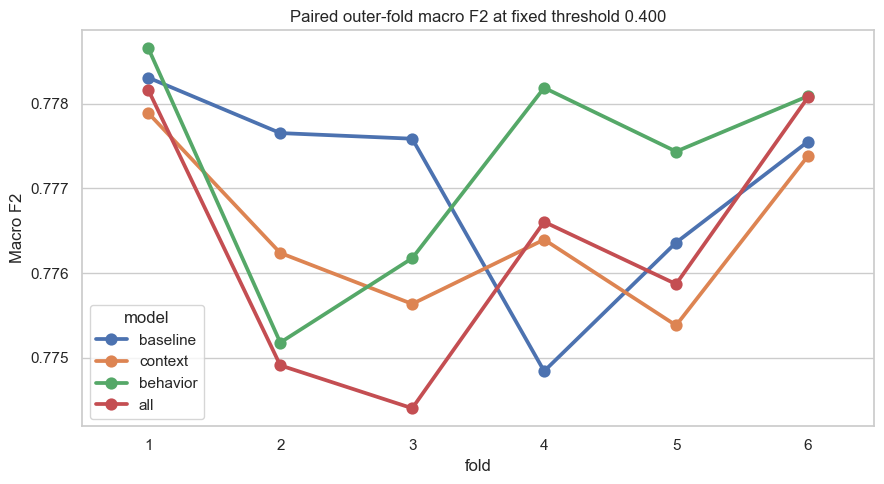

In [7]:
score_frames=[]
for name,frame in [("baseline",baseline_scores),("context",context_scores),
                   ("behavior",behavior_scores),("all",all_scores)]:
    score_frames.append(frame.assign(model=name))
score_table=pd.concat(score_frames,ignore_index=True)
ranking=(score_table.groupby("model",as_index=False)
         .agg(mean_macro_F2=("macro_F2","mean"),std_macro_F2=("macro_F2","std"),
              mean_F2_legitimate=("F2_legitimate","mean"),
              mean_F2_cheater=("F2_cheater","mean")))
ranking["delta_vs_baseline"]=ranking.mean_macro_F2-baseline_scores.macro_F2.mean()
display(ranking.sort_values("mean_macro_F2",ascending=False).round(5))
paired=score_table.pivot(index="fold",columns="model",values="macro_F2")
display(paired.round(5))

error_rows=[]
base=baseline[["fold","row_index","true","pred_fixed"]].rename(columns={"pred_fixed":"baseline_pred"})
for name,frame in [("context",context_oof),("behavior",behavior_oof),("all",all_oof)]:
    merged=base.merge(frame[["fold","row_index","pred_fixed"]],on=["fold","row_index"],validate="one_to_one")
    old_wrong=merged.baseline_pred.ne(merged.true)
    new_wrong=merged.pred_fixed.ne(merged.true)
    error_rows.append({"model":name,"baseline_errors_fixed":int(old_wrong.sum()),
                       "fixed_errors":int((old_wrong & ~new_wrong).sum()),
                       "new_errors":int((~old_wrong & new_wrong).sum()),
                       "candidate_errors":int(new_wrong.sum()),
                       "paired_fold_wins":int((paired[name]>paired.baseline).sum())})
display(pd.DataFrame(error_rows))

fig,ax=plt.subplots(figsize=(9,5))
sns.pointplot(data=score_table,x="fold",y="macro_F2",hue="model",markers="o",ax=ax)
ax.set(title="Paired outer-fold macro F2 at fixed threshold 0.400",ylabel="Macro F2")
plt.tight_layout();plt.show()

## 7. Read the saved evaluation index

The index groups scores by metric. The new fixed-threshold CV metric must not be ranked directly against the earlier inner-CV-tuned `macro_F2_outer_cv6` score as though their protocols were identical.

In [8]:
index=read_evaluation_index(1)
names=[f"t1_lgbm_{label}_fixed040_cv6_v3" for label in VARIANTS]
display(pd.DataFrame([{"name":name,**index["evaluations"][name]}
                      for name in names])[["name","metric","score"]].sort_values("score",ascending=False))
print("Best by new metric:",index["best_by_metric"].get("macro_F2_outer_cv6_fixed040"))

,name,metric,score
1,t1_lgbm_behavior_fixed040_cv6_v3,macro_F2_outer_cv6_fixed040,0.777288
0,t1_lgbm_context_fixed040_cv6_v3,macro_F2_outer_cv6_fixed040,0.776487
2,t1_lgbm_all_fixed040_cv6_v3,macro_F2_outer_cv6_fixed040,0.776338


Best by new metric: t1_lgbm_shallower_more_trees_fixed040_cv6_v3


## 8. Threshold-tuned behavior candidate

The behavior-only feature set was the only fixed-threshold candidate above baseline, by a small amount. Check it using the selected model's **same outer and inner CV threshold procedure** before comparing to its 0.77733 mean. This was chosen after viewing the fixed-threshold results, so the follow-up remains exploratory. Each outer validation fold is used only for scoring.

In [9]:
from sklearn.model_selection import StratifiedKFold, TunedThresholdClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer

TUNED_NAME="t1_lgbm_behavior_threshold_cv6_v3"
tuned_model_path=TASK/"save"/f"{TUNED_NAME}.joblib"
tuned_card_path=TASK/"save"/f"{TUNED_NAME}.json"
tuned_eval_path=TASK/"save"/f"{TUNED_NAME}-evaluation.json"
tuned_oof_path=result_dir/f"{TUNED_NAME}-oof.parquet"
tuned_oof_card_path=result_dir/f"{TUNED_NAME}-oof.json"
tuned_features=VARIANTS["behavior"]
tuned_key={"data_name":DATA_NAME,"data_created_at":data_card["created_at"],
           "source_name":source_name,"source_created_at":source_card["created_at"],
           "seed":SEED,"outer":"3-fold x 2 repeats","inner":"3-fold threshold CV",
           "thresholds":list(np.linspace(.10,.90,33)),"features":tuned_features}

def make_tuned_estimator():
    selector=ColumnTransformer([("keep","passthrough",tuned_features)],remainder="drop",
                               verbose_feature_names_out=False).set_output(transform="pandas")
    estimator=Pipeline([("select",selector),("classifier",clone(source_model))])
    return TunedThresholdClassifierCV(
        estimator=estimator,
        scoring=make_scorer(fbeta_score,beta=2,average="macro",zero_division=0),
        thresholds=np.linspace(.10,.90,33),
        cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED),
        refit=True,n_jobs=1)

if tuned_oof_path.exists()!=tuned_oof_card_path.exists():
    raise RuntimeError("Incomplete tuned OOF artifact")
if tuned_oof_path.exists():
    saved=json.loads(tuned_oof_card_path.read_text(encoding="utf-8"))
    assert saved["key"]==tuned_key
    tuned_oof=pd.read_parquet(tuned_oof_path)
    print("Loaded tuned OOF")
else:
    if tuned_model_path.exists() or tuned_card_path.exists() or tuned_eval_path.exists():
        raise RuntimeError("Saved model without tuned OOF")
    X=train[test.columns.drop(ID)]
    parts=[]
    for fold,(train_idx,valid_idx) in enumerate(splits,1):
        model=make_tuned_estimator()
        model.fit(X.iloc[train_idx],y.iloc[train_idx])
        valid_X=X.iloc[valid_idx]
        parts.append(pd.DataFrame({"row_index":valid_idx,"fold":fold,
            "true":y.iloc[valid_idx].to_numpy(),
            "prob":model.predict_proba(valid_X)[:,1],
            "pred":model.predict(valid_X).astype("int8"),
            "threshold":model.best_threshold_}))
        print("Tuned behavior fold",fold,"done")
    tuned_oof=pd.concat(parts,ignore_index=True)
    tuned_oof.to_parquet(tuned_oof_path,index=False)
    tuned_oof_card_path.write_text(json.dumps({"key":tuned_key,"rows":len(tuned_oof)},indent=2),encoding="utf-8")
assert len(tuned_oof)==2*len(train)
for fold,(_,valid_idx) in enumerate(splits,1):
    part=tuned_oof.loc[tuned_oof.fold==fold].sort_values("row_index")
    assert np.array_equal(part.row_index.to_numpy(),np.sort(valid_idx))
    assert np.array_equal(part.true.to_numpy(),y.iloc[part.row_index].to_numpy())
tuned_scores=fold_scores(tuned_oof,"pred")
tuned_mean=float(tuned_scores.macro_F2.mean())
if tuned_model_path.exists() and tuned_card_path.exists() and tuned_eval_path.exists():
    saved_card=json.loads(tuned_card_path.read_text(encoding="utf-8"))
    saved_eval=json.loads(tuned_eval_path.read_text(encoding="utf-8"))
    assert saved_card["data_name"]==DATA_NAME and saved_card["card"]["features"]==tuned_features
    assert saved_eval["metric"]=="macro_F2_outer_cv6"
    assert abs(saved_eval["score"]-tuned_mean)<1e-12
    print("Loaded tuned model and evaluation")
elif tuned_model_path.exists() or tuned_card_path.exists() or tuned_eval_path.exists():
    raise RuntimeError("Incomplete tuned saved result")
else:
    full_model=make_tuned_estimator()
    full_model.fit(train[test.columns.drop(ID)],y)
    save_model(task=1,name=TUNED_NAME,model=full_model,data_name=DATA_NAME,
        card={"idea":"Behavior-only features with fold-local threshold tuning",
              "source_model":source_name,"features":tuned_features,"seed":SEED,
              "validation":"3-fold x 2 repeats; inner 3-fold threshold CV",
              "full_data_threshold":float(full_model.best_threshold_)})
    evaluate_model(task=1,name=TUNED_NAME,score=tuned_mean,metric_name="macro_F2_outer_cv6",
        higher_is_better=True,card={"split":"paired outer CV; same accounts in both repeats",
                                  "fold_scores":tuned_scores.to_dict("records"),
                                  "note":"Procedure estimate, not holdout score for full-data model"})
    print("Saved tuned model and evaluation")
display(tuned_scores.round(5))
comparison=tuned_scores[["fold","macro_F2"]].merge(
    pd.DataFrame(json.loads((TASK/"models"/"results"/"round3_lgbm_combined_pruned_cv6.json").read_text(encoding="utf-8"))["folds"])
        [["fold","macro_F2"]],on="fold",suffixes=("_behavior","_selected"))
comparison["delta"]=comparison.macro_F2_behavior-comparison.macro_F2_selected
display(comparison.round(5))
print("Tuned behavior mean:",round(tuned_mean,5),
      "selected model mean:",round(comparison.macro_F2_selected.mean(),5),
      "mean paired delta:",round(comparison.delta.mean(),5),
      "wins:",int((comparison.delta>0).sum()),"of 6")

Loaded tuned OOF
Loaded tuned model and evaluation


,fold,macro_F2,F2_legitimate,F2_cheater
0,1,0.77766,0.79507,0.76025
1,2,0.77518,0.81799,0.73236
2,3,0.77690,0.79907,0.75473
3,4,0.77589,0.79419,0.75760
4,5,0.77770,0.80029,0.75512
5,6,0.77809,0.81923,0.73696


,fold,macro_F2_behavior,macro_F2_selected,delta
0,1,0.77766,0.77831,-0.00065
1,2,0.77518,0.77765,-0.00248
2,3,0.77690,0.77723,-0.00033
3,4,0.77589,0.77484,0.00105
4,5,0.77770,0.77799,-0.00029
5,6,0.77809,0.77795,0.00014


Tuned behavior mean: 0.7769 selected model mean: 0.77733 mean paired delta: -0.00042 wins: 2 of 6


### Round 5 interpretation

Read the paired table above. The fixed-threshold ablations and the tuned follow-up use repeated folds of the same labeled accounts, so small differences remain exploratory. A new local best must improve the matched threshold-tuning protocol consistently, not only a different metric or a reused holdout.

## 9. Fixed blends of existing OOF probabilities

The prior 50/50 selected/original blend was the strongest exploratory OOF result (0.77841). Compare it with a few **fixed** ways to include the new behavior model. No refit or saved ensemble is made here. These candidates are examined after observing earlier results, so a tiny win is not confirmation.

In [10]:
original_parts=[]
for suffix in ["","_repeat2"]:
    original_parts.append(pd.read_parquet(result_dir/f"round4_lgbm_original{suffix}_oof_v1.parquet"))
original_oof=pd.concat(original_parts,ignore_index=True)
blend_base=baseline[["fold","row_index","true","prob","threshold"]].merge(
    original_oof[["fold","row_index","true","prob","threshold"]],
    on=["fold","row_index"],validate="one_to_one",suffixes=("_pruned","_original"))
blend_base=blend_base.merge(tuned_oof[["fold","row_index","true","prob","threshold"]],
                            on=["fold","row_index"],validate="one_to_one")
assert blend_base.true_pruned.equals(blend_base.true_original)
assert blend_base.true_pruned.equals(blend_base.true)
BLENDS={"prior_50_50":(.5,.5,0),"pruned_behavior_50_50":(.5,0,.5),
        "original_behavior_50_50":(0,.5,.5),"equal_three":(1/3,1/3,1/3),
        "prior_plus_behavior_25pct":(.375,.375,.25)}
blend_rows=[]
for name,(wp,wo,wb) in BLENDS.items():
    probability=wp*blend_base.prob_pruned+wo*blend_base.prob_original+wb*blend_base.prob
    threshold=wp*blend_base.threshold_pruned+wo*blend_base.threshold_original+wb*blend_base.threshold
    prediction=(probability>=threshold).astype(int)
    for fold,idx in blend_base.groupby("fold").groups.items():
        blend_rows.append({"blend":name,"fold":fold,"macro_F2":fbeta_score(
            blend_base.loc[idx,"true"],prediction.loc[idx],beta=2,average="macro",zero_division=0)})
blend_scores=pd.DataFrame(blend_rows)
blend_summary=blend_scores.groupby("blend").macro_F2.agg(["mean","std"]).sort_values("mean",ascending=False)
display(blend_summary.round(6))
display(blend_scores.pivot(index="fold",columns="blend",values="macro_F2").round(5))
print("Best tested minus prior blend:",round(blend_summary["mean"].max()-blend_summary.loc["prior_50_50","mean"],6))

,mean,std
blend,,
prior_plus_behavior_25pct,0.778460,0.001113
prior_50_50,0.778411,0.001014
equal_three,0.778230,0.000961
pruned_behavior_50_50,0.777993,0.001050
original_behavior_50_50,0.777705,0.001217


blend,equal_three,original_behavior_50_50,prior_50_50,prior_plus_behavior_25pct,pruned_behavior_50_50
fold,,,,,
1,0.77863,0.77881,0.77969,0.77920,0.77904
2,0.77730,0.77641,0.77861,0.77887,0.77725
3,0.77754,0.77638,0.77814,0.77702,0.77776
4,0.77733,0.77707,0.77676,0.77705,0.77641
5,0.77947,0.77865,0.77915,0.77929,0.77900
6,0.77911,0.77892,0.77812,0.77932,0.77851


Best tested minus prior blend: 4.9e-05


## 10. Capacity check on the selected 38 features

The context features lost and the behavior gain disappeared after threshold tuning. Test whether the selected 38-feature LightGBM is limited by its current tree settings: smaller leaves, more boosting rounds, or shallower trees. Keep the feature set, folds, and threshold 0.400 fixed. These settings are exploratory and were chosen before seeing their fold scores.

In [11]:
CAPACITY_SETTINGS={
    "small_leaf":{"min_child_samples":30},
    "more_trees":{"n_estimators":700},
    "shallower_more_trees":{"num_leaves":31,"n_estimators":700},
}

def run_capacity(label,params):
    name=f"t1_lgbm_{label}_fixed040_cv6_v3"
    model_path=TASK/"save"/f"{name}.joblib"
    card_path=TASK/"save"/f"{name}.json"
    eval_path=TASK/"save"/f"{name}-evaluation.json"
    oof_path=result_dir/f"{name}-oof.parquet"
    oof_card_path=result_dir/f"{name}-oof.json"
    key={"data_name":DATA_NAME,"data_created_at":data_card["created_at"],
         "source_name":source_name,"source_created_at":source_card["created_at"],
         "seed":SEED,"outer":"3-fold x 2 repeats","threshold":FIXED_THRESHOLD,
         "features":BASE,"params":params}
    estimator=clone(source_model).set_params(**params)
    if oof_path.exists()!=oof_card_path.exists():
        raise RuntimeError(f"Incomplete OOF artifact: {name}")
    if oof_path.exists():
        assert json.loads(oof_card_path.read_text(encoding="utf-8"))["key"]==key
        oof=pd.read_parquet(oof_path)
        print("Loaded OOF:",name)
    else:
        if model_path.exists() or card_path.exists() or eval_path.exists():
            raise RuntimeError(f"Saved model without OOF: {name}")
        X=train[BASE]
        parts=[]
        for fold,(train_idx,valid_idx) in enumerate(splits,1):
            model=clone(estimator)
            model.fit(X.iloc[train_idx],y.iloc[train_idx])
            prob=model.predict_proba(X.iloc[valid_idx])[:,1]
            parts.append(pd.DataFrame({"row_index":valid_idx,"fold":fold,
                "true":y.iloc[valid_idx].to_numpy(),"prob":prob,
                "pred_fixed":(prob>=FIXED_THRESHOLD).astype("int8")}))
            print(name,"fold",fold,"done")
        oof=pd.concat(parts,ignore_index=True)
        oof.to_parquet(oof_path,index=False)
        oof_card_path.write_text(json.dumps({"key":key,"rows":len(oof)},indent=2),encoding="utf-8")
    assert len(oof)==2*len(train)
    for fold,(_,valid_idx) in enumerate(splits,1):
        part=oof.loc[oof.fold==fold].sort_values("row_index")
        assert np.array_equal(part.row_index.to_numpy(),np.sort(valid_idx))
        assert np.array_equal(part.true.to_numpy(),y.iloc[part.row_index].to_numpy())
    scores=fold_scores(oof,"pred_fixed")
    score=float(scores.macro_F2.mean())
    if model_path.exists() and card_path.exists() and eval_path.exists():
        card=json.loads(card_path.read_text(encoding="utf-8"))
        evaluation=json.loads(eval_path.read_text(encoding="utf-8"))
        assert card["data_name"]==DATA_NAME and card["card"]["params"]==params
        assert evaluation["metric"]=="macro_F2_outer_cv6_fixed040" and abs(evaluation["score"]-score)<1e-12
    elif model_path.exists() or card_path.exists() or eval_path.exists():
        raise RuntimeError(f"Incomplete saved result: {name}")
    else:
        selector=ColumnTransformer([("keep","passthrough",BASE)],remainder="drop",
                                   verbose_feature_names_out=False).set_output(transform="pandas")
        full_model=Pipeline([("select",selector),("classifier",FixedThresholdClassifier(
            estimator=clone(estimator),threshold=FIXED_THRESHOLD))])
        full_model.fit(train[test.columns.drop(ID)],y)
        save_model(task=1,name=name,model=full_model,data_name=DATA_NAME,
            card={"idea":f"Capacity check: {label}","source_model":source_name,
                  "features":BASE,"params":params,"threshold":FIXED_THRESHOLD,"seed":SEED,
                  "validation":"3-fold x 2 repeats, fixed threshold"})
        evaluate_model(task=1,name=name,score=score,metric_name="macro_F2_outer_cv6_fixed040",
            higher_is_better=True,card={"split":"paired outer CV; same accounts in both repeats",
                                      "fold_scores":scores.to_dict("records"),
                                      "note":"Procedure estimate, not holdout score for full-data model"})
        print("Saved model and evaluation:",name)
    print(name,"mean macro F2:",round(score,5),"delta vs fixed baseline:",
          round(score-baseline_scores.macro_F2.mean(),5))
    return oof,scores

### Smaller minimum leaf

In [12]:
small_leaf_oof,small_leaf_scores=run_capacity("small_leaf",CAPACITY_SETTINGS["small_leaf"])

Loaded OOF: t1_lgbm_small_leaf_fixed040_cv6_v3
t1_lgbm_small_leaf_fixed040_cv6_v3 mean macro F2: 0.77664 delta vs fixed baseline: -0.00041


### More boosting rounds

In [13]:
more_trees_oof,more_trees_scores=run_capacity("more_trees",CAPACITY_SETTINGS["more_trees"])

Loaded OOF: t1_lgbm_more_trees_fixed040_cv6_v3


t1_lgbm_more_trees_fixed040_cv6_v3 mean macro F2: 0.77548 delta vs fixed baseline: -0.00158


### Shallower trees with more rounds

In [14]:
shallower_more_trees_oof,shallower_more_trees_scores=run_capacity("shallower_more_trees",CAPACITY_SETTINGS["shallower_more_trees"])

Loaded OOF: t1_lgbm_shallower_more_trees_fixed040_cv6_v3


t1_lgbm_shallower_more_trees_fixed040_cv6_v3 mean macro F2: 0.77784 delta vs fixed baseline: 0.00079


### Capacity comparison

Rank against the fixed-threshold baseline on paired folds. Any promising setting needs a matched inner-CV threshold check before replacing the selected model.

In [15]:
capacity_scores=pd.concat([
    baseline_scores.assign(model="baseline"),
    small_leaf_scores.assign(model="small_leaf"),
    more_trees_scores.assign(model="more_trees"),
    shallower_more_trees_scores.assign(model="shallower_more_trees")],ignore_index=True)
capacity_summary=(capacity_scores.groupby("model",as_index=False)
                  .agg(mean_macro_F2=("macro_F2","mean"),
                       mean_F2_legitimate=("F2_legitimate","mean"),
                       mean_F2_cheater=("F2_cheater","mean")))
capacity_summary["delta_vs_baseline"]=capacity_summary.mean_macro_F2-baseline_scores.macro_F2.mean()
display(capacity_summary.sort_values("mean_macro_F2",ascending=False).round(5))
display(capacity_scores.pivot(index="fold",columns="model",values="macro_F2").round(5))

,model,mean_macro_F2,mean_F2_legitimate,mean_F2_cheater,delta_vs_baseline
2,shallower_more_trees,0.77784,0.82019,0.73549,0.00079
0,baseline,0.77705,0.81824,0.73586,0.00000
3,small_leaf,0.77664,0.81824,0.73504,-0.00041
1,more_trees,0.77548,0.81863,0.73232,-0.00158


model,baseline,more_trees,shallower_more_trees,small_leaf
fold,,,,
1,0.77831,0.77644,0.77946,0.77794
2,0.77765,0.77568,0.77813,0.77537
3,0.77759,0.77582,0.77748,0.77628
4,0.77484,0.77424,0.77636,0.77639
5,0.77636,0.77500,0.77743,0.77557
6,0.77755,0.77567,0.77819,0.77828


## 11. Threshold-tuned shallower LightGBM

The 31-leaf/700-round candidate won 5/6 fixed-threshold folds. Apply the selected procedure's **same inner 3-fold threshold selection** on each of the six outer folds. This is a follow-up selected after seeing the fixed-threshold scores, so any small improvement remains exploratory.

In [16]:
from sklearn.model_selection import StratifiedKFold, TunedThresholdClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer

TUNED_NAME="t1_lgbm_shallower_more_trees_threshold_cv6_v3"
tuned_model_path=TASK/"save"/f"{TUNED_NAME}.joblib"
tuned_card_path=TASK/"save"/f"{TUNED_NAME}.json"
tuned_eval_path=TASK/"save"/f"{TUNED_NAME}-evaluation.json"
tuned_oof_path=result_dir/f"{TUNED_NAME}-oof.parquet"
tuned_oof_card_path=result_dir/f"{TUNED_NAME}-oof.json"
tuned_features=BASE
tuned_key={"data_name":DATA_NAME,"data_created_at":data_card["created_at"],
           "source_name":source_name,"source_created_at":source_card["created_at"],
           "seed":SEED,"outer":"3-fold x 2 repeats","inner":"3-fold threshold CV",
           "thresholds":list(np.linspace(.10,.90,33)),"features":tuned_features,"params":{"num_leaves":31,"n_estimators":700}}

def make_tuned_estimator():
    selector=ColumnTransformer([("keep","passthrough",tuned_features)],remainder="drop",
                               verbose_feature_names_out=False).set_output(transform="pandas")
    estimator=Pipeline([("select",selector),("classifier",clone(source_model).set_params(num_leaves=31,n_estimators=700))])
    return TunedThresholdClassifierCV(
        estimator=estimator,
        scoring=make_scorer(fbeta_score,beta=2,average="macro",zero_division=0),
        thresholds=np.linspace(.10,.90,33),
        cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED),
        refit=True,n_jobs=1)

if tuned_oof_path.exists()!=tuned_oof_card_path.exists():
    raise RuntimeError("Incomplete tuned OOF artifact")
if tuned_oof_path.exists():
    saved=json.loads(tuned_oof_card_path.read_text(encoding="utf-8"))
    assert saved["key"]==tuned_key
    tuned_oof=pd.read_parquet(tuned_oof_path)
    print("Loaded tuned OOF")
else:
    if tuned_model_path.exists() or tuned_card_path.exists() or tuned_eval_path.exists():
        raise RuntimeError("Saved model without tuned OOF")
    X=train[test.columns.drop(ID)]
    parts=[]
    for fold,(train_idx,valid_idx) in enumerate(splits,1):
        model=make_tuned_estimator()
        model.fit(X.iloc[train_idx],y.iloc[train_idx])
        valid_X=X.iloc[valid_idx]
        parts.append(pd.DataFrame({"row_index":valid_idx,"fold":fold,
            "true":y.iloc[valid_idx].to_numpy(),
            "prob":model.predict_proba(valid_X)[:,1],
            "pred":model.predict(valid_X).astype("int8"),
            "threshold":model.best_threshold_}))
        print("Tuned shallower fold",fold,"done")
    tuned_oof=pd.concat(parts,ignore_index=True)
    tuned_oof.to_parquet(tuned_oof_path,index=False)
    tuned_oof_card_path.write_text(json.dumps({"key":tuned_key,"rows":len(tuned_oof)},indent=2),encoding="utf-8")
assert len(tuned_oof)==2*len(train)
for fold,(_,valid_idx) in enumerate(splits,1):
    part=tuned_oof.loc[tuned_oof.fold==fold].sort_values("row_index")
    assert np.array_equal(part.row_index.to_numpy(),np.sort(valid_idx))
    assert np.array_equal(part.true.to_numpy(),y.iloc[part.row_index].to_numpy())
tuned_scores=fold_scores(tuned_oof,"pred")
tuned_mean=float(tuned_scores.macro_F2.mean())
if tuned_model_path.exists() and tuned_card_path.exists() and tuned_eval_path.exists():
    saved_card=json.loads(tuned_card_path.read_text(encoding="utf-8"))
    saved_eval=json.loads(tuned_eval_path.read_text(encoding="utf-8"))
    assert saved_card["data_name"]==DATA_NAME and saved_card["card"]["features"]==tuned_features
    assert saved_eval["metric"]=="macro_F2_outer_cv6"
    assert abs(saved_eval["score"]-tuned_mean)<1e-12
    print("Loaded tuned model and evaluation")
elif tuned_model_path.exists() or tuned_card_path.exists() or tuned_eval_path.exists():
    raise RuntimeError("Incomplete tuned saved result")
else:
    full_model=make_tuned_estimator()
    full_model.fit(train[test.columns.drop(ID)],y)
    save_model(task=1,name=TUNED_NAME,model=full_model,data_name=DATA_NAME,
        card={"idea":"Shallower 38-feature LightGBM with fold-local threshold tuning",
              "source_model":source_name,"features":tuned_features,"params":{"num_leaves":31,"n_estimators":700},"seed":SEED,
              "validation":"3-fold x 2 repeats; inner 3-fold threshold CV",
              "full_data_threshold":float(full_model.best_threshold_)})
    evaluate_model(task=1,name=TUNED_NAME,score=tuned_mean,metric_name="macro_F2_outer_cv6",
        higher_is_better=True,card={"split":"paired outer CV; same accounts in both repeats",
                                  "fold_scores":tuned_scores.to_dict("records"),
                                  "note":"Procedure estimate, not holdout score for full-data model"})
    print("Saved tuned model and evaluation")
display(tuned_scores.round(5))
comparison=tuned_scores[["fold","macro_F2"]].merge(
    pd.DataFrame(json.loads((TASK/"models"/"results"/"round3_lgbm_combined_pruned_cv6.json").read_text(encoding="utf-8"))["folds"])
        [["fold","macro_F2"]],on="fold",suffixes=("_shallower","_selected"))
comparison["delta"]=comparison.macro_F2_shallower-comparison.macro_F2_selected
display(comparison.round(5))
print("Tuned shallower mean:",round(tuned_mean,5),
      "selected model mean:",round(comparison.macro_F2_selected.mean(),5),
      "mean paired delta:",round(comparison.delta.mean(),5),
      "wins:",int((comparison.delta>0).sum()),"of 6")

Loaded tuned OOF


Loaded tuned model and evaluation


,fold,macro_F2,F2_legitimate,F2_cheater
0,1,0.77752,0.79531,0.75973
1,2,0.77729,0.79717,0.75742
2,3,0.77827,0.79876,0.75777
3,4,0.77533,0.79317,0.75750
4,5,0.77830,0.80075,0.75586
5,6,0.77819,0.81996,0.73642


,fold,macro_F2_shallower,macro_F2_selected,delta
0,1,0.77752,0.77831,-0.00079
1,2,0.77729,0.77765,-0.00036
2,3,0.77827,0.77723,0.00104
3,4,0.77533,0.77484,0.00049
4,5,0.77830,0.77799,0.00032
5,6,0.77819,0.77795,0.00024


Tuned shallower mean: 0.77748 selected model mean: 0.77733 mean paired delta: 0.00016 wins: 4 of 6


### Round 5 final comparison

Compare the paired tuned scores and keep holdout, fixed-threshold CV, and threshold-tuned CV distinct. Repeated folds reuse accounts. A result must be interpreted with the earlier searches and selection steps in mind.

## 12. Shallower blends from saved OOF probabilities

Compare a short set of fixed-weight shallow-model blends with the earlier 50/50 pruned/original blend. The models and OOF predictions are already saved; this cell performs no fitting. A few ten-thousandths of macro F₂ after examining several blends is an exploratory hint, not a confirmed gain.

In [17]:
shallow_blend_base=baseline[["fold","row_index","true","prob","threshold"]].merge(
    original_oof[["fold","row_index","true","prob","threshold"]],
    on=["fold","row_index"],validate="one_to_one",suffixes=("_pruned","_original"))
shallow_blend_base=shallow_blend_base.merge(
    tuned_oof[["fold","row_index","true","prob","threshold"]],
    on=["fold","row_index"],validate="one_to_one")
assert shallow_blend_base.true_pruned.equals(shallow_blend_base.true_original)
assert shallow_blend_base.true_pruned.equals(shallow_blend_base.true)
SHALLOW_BLENDS={"prior_50_50":(.5,.5,0),"pruned_shallow_50_50":(.5,0,.5),
    "original_shallow_50_50":(0,.5,.5),"equal_three":(1/3,1/3,1/3),
    "prior_plus_shallow_25pct":(.375,.375,.25)}
shallow_blend_rows=[]
for name,(wp,wo,ws) in SHALLOW_BLENDS.items():
    probability=wp*shallow_blend_base.prob_pruned+wo*shallow_blend_base.prob_original+ws*shallow_blend_base.prob
    threshold=wp*shallow_blend_base.threshold_pruned+wo*shallow_blend_base.threshold_original+ws*shallow_blend_base.threshold
    prediction=(probability>=threshold).astype(int)
    for fold,idx in shallow_blend_base.groupby("fold").groups.items():
        shallow_blend_rows.append({"blend":name,"fold":fold,"macro_F2":fbeta_score(
            shallow_blend_base.loc[idx,"true"],prediction.loc[idx],beta=2,
            average="macro",zero_division=0)})
shallow_blend_scores=pd.DataFrame(shallow_blend_rows)
display(shallow_blend_scores.groupby("blend").macro_F2.agg(["mean","std"])
        .sort_values("mean",ascending=False).round(6))
display(shallow_blend_scores.pivot(index="fold",columns="blend",values="macro_F2").round(5))

,mean,std
blend,,
prior_plus_shallow_25pct,0.778651,0.001089
equal_three,0.778567,0.001328
pruned_shallow_50_50,0.778508,0.001403
prior_50_50,0.778411,0.001014
original_shallow_50_50,0.777935,0.000955


blend,equal_three,original_shallow_50_50,prior_50_50,prior_plus_shallow_25pct,pruned_shallow_50_50
fold,,,,,
1,0.77928,0.77817,0.77969,0.77923,0.77819
2,0.77836,0.77802,0.77861,0.77893,0.77876
3,0.77680,0.77676,0.77814,0.77716,0.77881
4,0.77737,0.77684,0.77676,0.77751,0.77593
5,0.77921,0.77879,0.77915,0.77907,0.78000
6,0.78039,0.77902,0.77812,0.78000,0.77936


## Round 5 readout

The context and combined feature sets lost to the selected 38-feature baseline. Behavior features gave a tiny gain at a fixed threshold but lost under matched threshold tuning. Of three capacity settings, only the shallower/longer LightGBM improved the fixed-threshold comparison (+0.00079, 5/6 folds); matched threshold tuning reduced its gain to +0.00016 (4/6 folds). The best examined shallow blend improved the prior blend by only about 0.00024 on the same reused accounts. These are research signals rather than a dependable new local best. Keep the previous 38-feature model as the standalone reference and the prior 50/50 blend as the strongest established exploratory ensemble. No Test labels or leaderboard feedback entered this round.

The next useful investigation is a fold-separated local-neighborhood audit of the persistent confident errors to assess whether very similar accounts carry mixed labels. Further arbitrary ratios, threshold grids, or tiny blend-weight changes are low priority given the results above.

In [18]:
final_index=read_evaluation_index(1)
round5_names=[name for name in final_index["evaluations"] if name.endswith("_v3") and name.startswith("t1_lgbm_")]
display(pd.DataFrame([{"name":name,"metric":final_index["evaluations"][name]["metric"],
                       "score":final_index["evaluations"][name]["score"]}
                      for name in round5_names]).sort_values(["metric","score"],ascending=[True,False]))
print("Best saved model by each metric (metrics must not be mixed):")
display({key:value for key,value in final_index["best_by_metric"].items()
         if key in ["macro_F2_outer_cv6","macro_F2_outer_cv6_fixed040"]})

,name,metric,score
7,t1_lgbm_shallower_more_trees_threshold_cv6_v3,macro_F2_outer_cv6,0.777485
3,t1_lgbm_behavior_threshold_cv6_v3,macro_F2_outer_cv6,0.776905
6,t1_lgbm_shallower_more_trees_fixed040_cv6_v3,macro_F2_outer_cv6_fixed040,0.777840
1,t1_lgbm_behavior_fixed040_cv6_v3,macro_F2_outer_cv6_fixed040,0.777288
4,t1_lgbm_small_leaf_fixed040_cv6_v3,macro_F2_outer_cv6_fixed040,0.776640
0,t1_lgbm_context_fixed040_cv6_v3,macro_F2_outer_cv6_fixed040,0.776487
2,t1_lgbm_all_fixed040_cv6_v3,macro_F2_outer_cv6_fixed040,0.776338
5,t1_lgbm_more_trees_fixed040_cv6_v3,macro_F2_outer_cv6_fixed040,0.775475


Best saved model by each metric (metrics must not be mixed):


{'macro_F2_outer_cv6': 't1_lgbm_shallower_more_trees_threshold_cv6_v3',
 'macro_F2_outer_cv6_fixed040': 't1_lgbm_shallower_more_trees_fixed040_cv6_v3'}